# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** The goal is to predict whether a breast tumor is malignant or benign using 30 numerical features from breast mass images through supervised learning, specifically binary classification. A false negative is more serious because classifying a malignant tumor as benign may delay necessary treatment. The model's performance will be evaluated using accuracy, precision, recall, and F1-score, with emphasis on correctly identifying malignant cases.

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [69]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import VotingClassifier

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).

> *Using your own data?* Only this cell changes. For an ARFF file use `scipy.io.arff.loadarff`, and keep the rest of the workbook as is.

> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [70]:
# TODO: load the dataset and copy its DataFrame into df

data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [71]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows

print("Dimensions:")
print(df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nFirst Rows:")
print(df.head())

print("\nDataFrame Info:")
print(df.info())

Dimensions:
(569, 31)

Data Types:
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points

**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [72]:
# TODO: class counts and percentages

class_counts = df['target'].value_counts()
print("Class Counts:")
print(class_counts)

class_proportions = df['target'].value_counts(normalize=True)
print("\nClass Proportions:")
print(class_proportions)

print("\nClass Percentages:")
print(class_proportions * 100)

Class Counts:
target
1    357
0    212
Name: count, dtype: int64

Class Proportions:
target
1    0.627417
0    0.372583
Name: proportion, dtype: float64

Class Percentages:
target
1    62.741652
0    37.258348
Name: proportion, dtype: float64


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [73]:
# TODO: describe().T, then the 10 largest skewness values

display(df.describe().T)

skewness = df.drop(columns='target').skew()
display(skewness.abs().nlargest(10))

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


,0
area error,5.447186
concavity error,5.110463
fractal dimension error,3.923969
perimeter error,3.443615
radius error,3.088612
smoothness error,2.314450
symmetry error,2.195133
compactness error,1.902221
worst area,1.859373
worst fractal dimension,1.662579


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [74]:
# TODO: correlation with target, sorted
correlation = df.corr(numeric_only=True)['target'].drop('target').sort_values()

print("5 Most Negative Correlations:")
display(correlation.head(5))

print("5 Most Positive Correlations:")
display(correlation.tail(5).sort_values(ascending=False))

5 Most Negative Correlations:


,target
worst concave points,-0.793566
worst perimeter,-0.782914
mean concave points,-0.776614
worst radius,-0.776454
mean perimeter,-0.742636


5 Most Positive Correlations:


,target
smoothness error,0.067016
mean fractal dimension,0.012838
texture error,0.008303
symmetry error,0.006522
fractal dimension error,-0.077972


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:** The class proportions show a slight class imbalance, so accuracy alone may not be enough to evaluate the model. Metrics such as precision, recall, and F1-score can provide a clearer evaluation. The skewness indicates that some features are not normally distributed, so transformations may help improve model performance when needed.

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

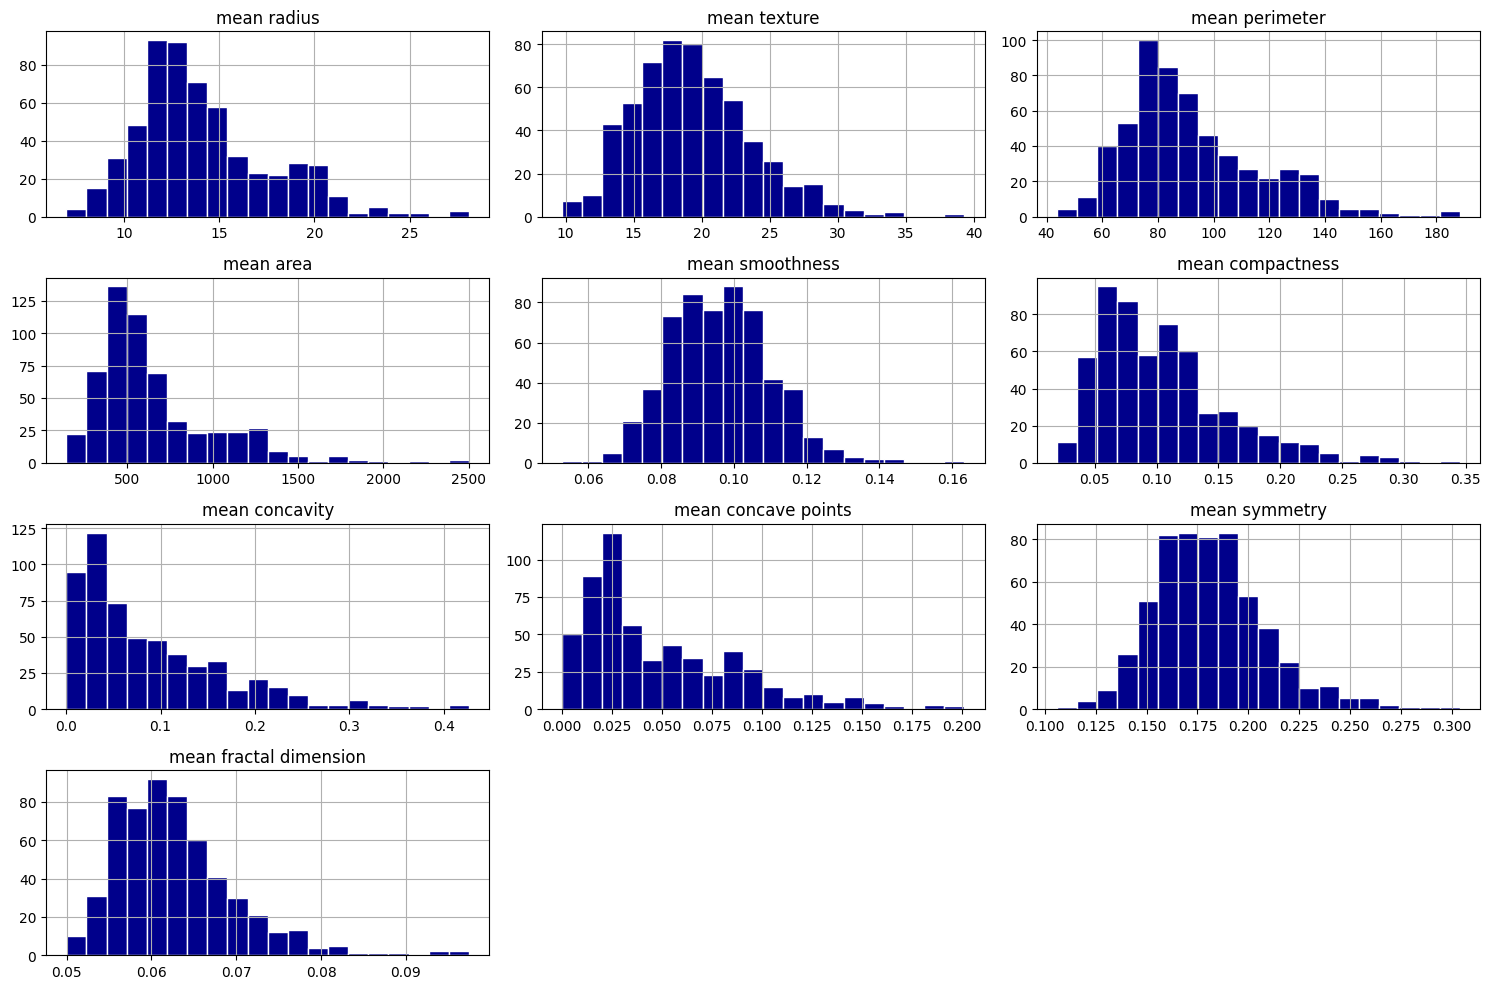

In [75]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)

df.filter(like="mean").hist(figsize=(15, 10), bins=20, color="darkblue", edgecolor="white")
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

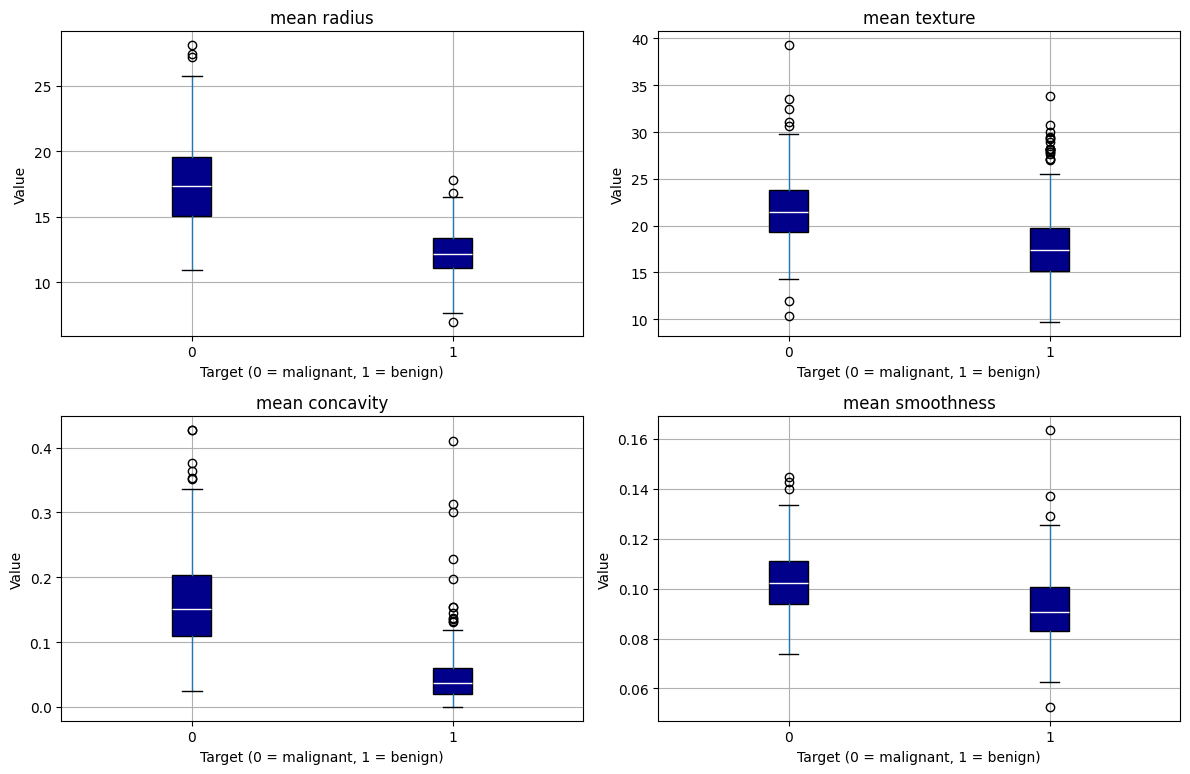

In [76]:
# TODO: one box plot per feature, grouped by target
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(features, axes.flatten()):
    df.boxplot(column=feature, by="target", ax=ax, patch_artist=True,
               boxprops=dict(facecolor="darkblue"),
               medianprops=dict(color="white"))
    ax.set_title(feature)
    ax.set_xlabel("Target (0 = malignant, 1 = benign)")
    ax.set_ylabel("Value")

plt.suptitle("")
plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

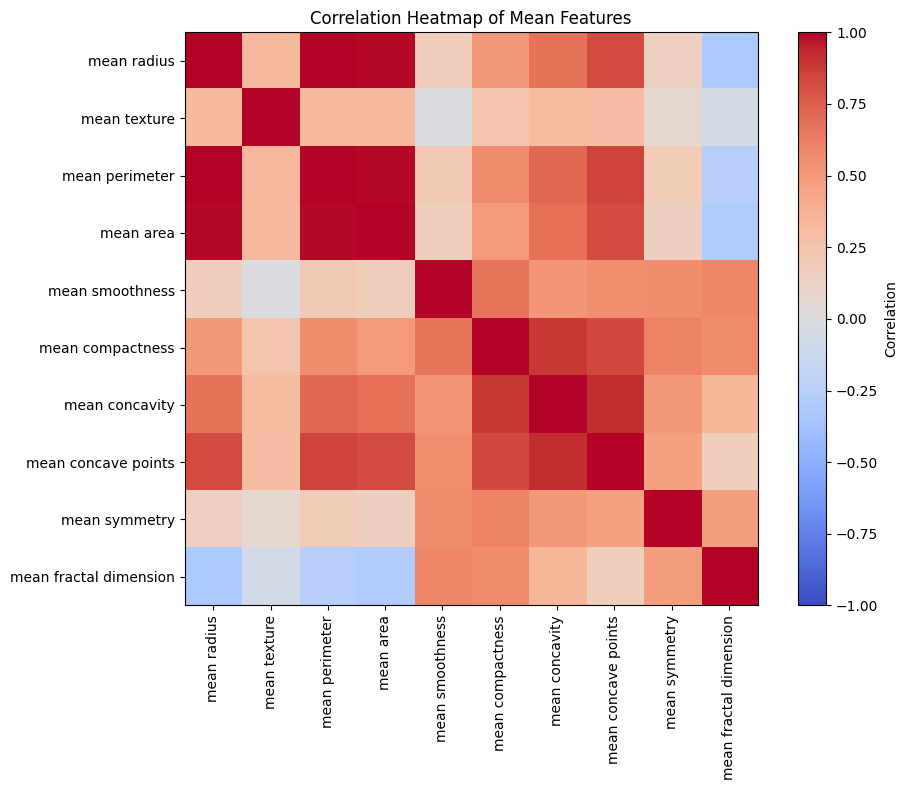

In [77]:
# TODO: correlation matrix of the "mean" features drawn with imshow

corr = df.filter(like="mean").corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap of Mean Features")
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

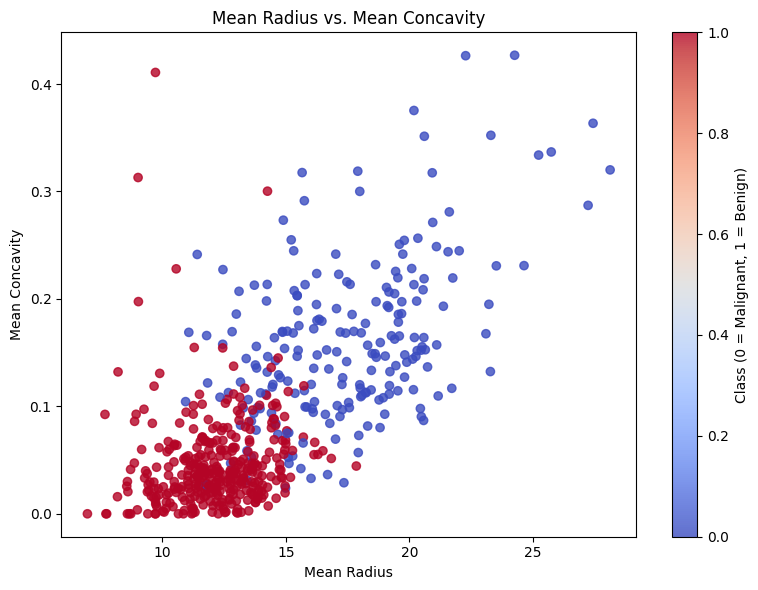

In [78]:
# TODO: coloured scatter plot with axis labels and a colourbar

plt.figure(figsize=(8, 6))
scatter = plt.scatter(df["mean radius"], df["mean concavity"],
                      c=df["target"], cmap="coolwarm", alpha=0.8)
plt.xlabel("Mean Radius")
plt.ylabel("Mean Concavity")
plt.title("Mean Radius vs. Mean Concavity")
plt.colorbar(scatter, label="Class (0 = Malignant, 1 = Benign)")
plt.tight_layout()
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:** Features such as mean radius and other size-related features may be redundant because they are highly correlated. Mean radius and mean concavity appear to separate the classes clearly, while mean smoothness shows more overlap.

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [79]:
# TODO: total missing values and duplicated rows

print("Total missing values:", df.isnull().sum().sum())
print("Duplicated rows:", df.duplicated().sum())

X = df.drop(columns="target")
y = df["target"]

Total missing values: 0
Duplicated rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [80]:
# TODO: IQR outlier count per feature

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

outlier_counts = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()

display(outlier_counts.nlargest(10))

,0
area error,65
radius error,38
perimeter error,38
worst area,35
smoothness error,30
compactness error,28
fractal dimension error,28
symmetry error,27
mean area,25
worst fractal dimension,24


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:** No, I would not delete the outlying rows because they may contain valid medical measurements that help distinguish malignant and benign tumors. Removing them could lead to information loss and affect model performance.

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [81]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95

corr_matrix = X.corr().abs()
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_features = upper_triangle.columns[
    (upper_triangle > 0.95).any()
]

display(upper_triangle.loc[:, high_corr_features].max().sort_values(ascending=False))

,0
mean perimeter,0.997855
worst perimeter,0.993708
mean area,0.987357
worst area,0.984015
perimeter error,0.972794
worst radius,0.969539
area error,0.951830


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [82]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores

selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)

scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
display(scores.head(10))

,0
worst concave points,964.385393
worst perimeter,897.944219
mean concave points,861.676020
worst radius,860.781707
mean perimeter,697.235272
worst area,661.600206
mean radius,646.981021
mean area,573.060747
mean concavity,533.793126
worst concavity,436.691939


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [83]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

rfe = RFE(estimator=LogisticRegression(max_iter=10000), n_features_to_select=10)
rfe.fit(X_scaled, y)

rfe_features = X.columns[rfe.support_].tolist()
display(rfe_features)

['mean concave points',
 'radius error',
 'area error',
 'compactness error',
 'worst radius',
 'worst texture',
 'worst perimeter',
 'worst area',
 'worst concavity',
 'worst concave points']

**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

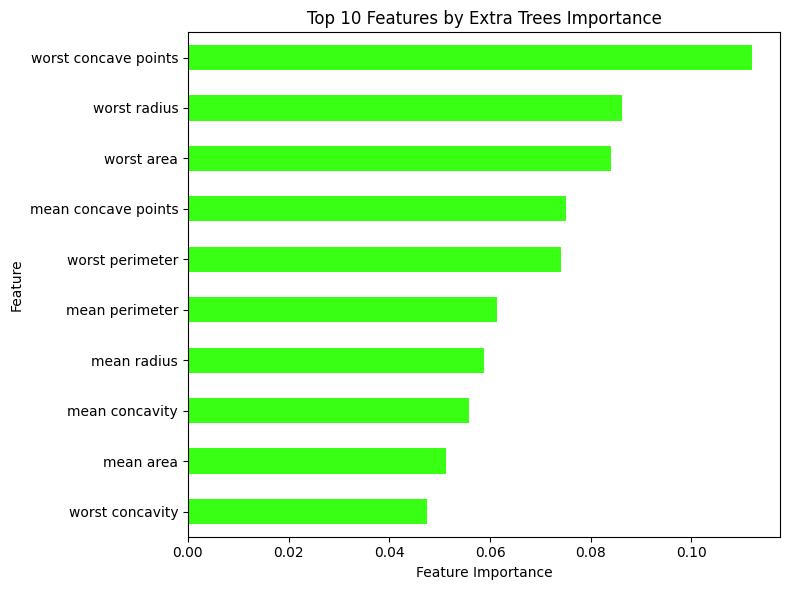

In [84]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10

model = ExtraTreesClassifier(n_estimators=200, random_state=7)
model.fit(X, y)

imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
top10 = imp.head(10).sort_values()

top10.plot(kind="barh", figsize=(8, 6), color="#39FF14")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features by Extra Trees Importance")
plt.tight_layout()
plt.show()

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [85]:
# TODO: vote across the three methods

kbest_features = scores.head(10).index.tolist()
et_features = imp.head(10).index.tolist()

votes = pd.Series(kbest_features + rfe_features + et_features).value_counts()
selected = votes[votes >= 2].index.tolist()

display(selected)

['worst concave points',
 'worst perimeter',
 'mean concave points',
 'worst radius',
 'worst area',
 'worst concavity',
 'mean perimeter',
 'mean radius',
 'mean area',
 'mean concavity']

> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [86]:
# TODO: train_test_split with stratify=y

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=7, stratify=y
)

print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [87]:
# TODO: fit both scalers on X_train and print the verifying statistics

standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

X_train_standard = standard_scaler.fit_transform(X_train)
X_train_minmax = minmax_scaler.fit_transform(X_train)

print("StandardScaler:")
display(pd.DataFrame(X_train_standard, columns=X_train.columns).iloc[:, :4].agg(["mean", "std"]).round(3))

print("MinMaxScaler:")
display(pd.DataFrame(X_train_minmax, columns=X_train.columns).iloc[:, :4].agg(["min", "max"]).round(3))

StandardScaler:


,mean radius,mean texture,mean perimeter,mean area
mean,0.000,-0.000,-0.000,-0.000
std,1.001,1.001,1.001,1.001


MinMaxScaler:


,mean radius,mean texture,mean perimeter,mean area
min,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [88]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance

pca = PCA()
pca.fit(X_train_standard)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Components retaining 95% variance:", n_components)

Components retaining 95% variance: 10


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [89]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

models = {
    "LR": LogisticRegression(max_iter=10000, random_state=seed),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC()
}


def spot_check(models, X_tr, scale):
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [90]:
# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled

raw_results = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

summary = pd.DataFrame({
    "raw": {name: scores.mean() for name, scores in raw_results.items()},
    "scaled": {name: scores.mean() for name, scores in scaled_results.items()}
})

display(summary)

,raw,scaled
LR,0.953768,0.982319
LDA,0.947246,0.947246
KNN,0.922947,0.964928
CART,0.927633,0.927633
NB,0.934058,0.932029
SVM,0.898696,0.975797


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:** KNN, Logistic Regression, and SVM generally benefit from scaling because they are sensitive to feature magnitudes. LDA may also benefit, while Decision Tree and Gaussian Naive Bayes usually require less scaling. The summary results confirm which models improved in this dataset.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [91]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results

selected_results = spot_check(models, X_train[selected], scale=True)

selected_summary = pd.DataFrame({
    "all_features_scaled": summary["scaled"],
    "selected_features_scaled": {
        name: scores.mean() for name, scores in selected_results.items()
    }
})

display(selected_summary)

,all_features_scaled,selected_features_scaled
LR,0.982319,0.960435
LDA,0.947246,0.942995
KNN,0.964928,0.942802
CART,0.927633,0.925266
NB,0.932029,0.951691
SVM,0.975797,0.953865


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

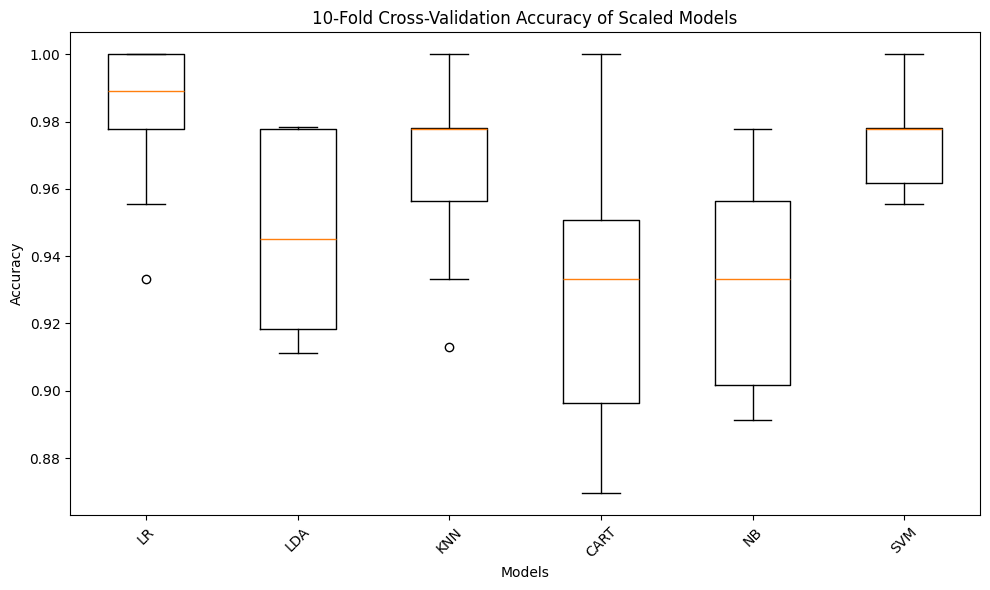

In [92]:
# TODO: box plot of the 10 fold scores per model

scaled_scores = spot_check(models, X_train, scale=True)

plt.figure(figsize=(10, 6))
plt.boxplot(scaled_scores.values(), tick_labels=scaled_scores.keys())
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.title("10-Fold Cross-Validation Accuracy of Scaled Models")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [93]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)

best_model_name = summary["scaled"].idxmax()
best_model = models[best_model_name]

pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", best_model)
])

scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "recall_malignant": make_scorer(recall_score, pos_label=0)
}

cv_results = cross_validate(
    pipeline,
    X_train,
    y_train,
    cv=kfold,
    scoring=scoring
)

print("Best scaled model:", best_model_name)
print("Accuracy:", cv_results["test_accuracy"].mean())
print("ROC-AUC:", cv_results["test_roc_auc"].mean())
print("Recall (malignant):", cv_results["test_recall_malignant"].mean())

Best scaled model: LR
Accuracy: 0.9823188405797101
ROC-AUC: 0.9921689365401333
Recall (malignant): 0.9647058823529413


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [94]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]

svm_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC())
])

param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"]
}

grid_search = GridSearchCV(
    svm_pipeline,
    param_grid,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

Best Parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best Cross-Validation Accuracy: 0.9801932367149758


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [95]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]

knn_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier())
])

param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"]
}

grid_search_knn = GridSearchCV(
    knn_pipeline,
    param_grid,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

grid_search_knn.fit(X_train, y_train)

print("Best Parameters:", grid_search_knn.best_params_)
print("Best Cross-Validation Accuracy:", grid_search_knn.best_score_)

Best Parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best Cross-Validation Accuracy: 0.9692753623188406


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [96]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier

ensembles = {
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=seed),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=seed),
    "Gradient Boosting": GradientBoostingClassifier(random_state=seed),
    "AdaBoost": AdaBoostClassifier(random_state=seed)
}

ensemble_results = spot_check(ensembles, X_train, scale=False)

ensemble_summary = pd.Series({
    name: scores.mean()
    for name, scores in ensemble_results.items()
}).sort_values(ascending=False)

display(ensemble_summary)

voting_model = VotingClassifier(
    estimators=[
        ("svm", grid_search.best_estimator_),
        ("knn", grid_search_knn.best_estimator_),
        ("rf", ensembles["Random Forest"])
    ],
    voting="hard"
)

voting_results = cross_val_score(
    voting_model,
    X_train,
    y_train,
    cv=kfold,
    scoring="accuracy"
)

print("Voting Ensemble Accuracy:", voting_results.mean())

,0
Extra Trees,0.971401
Gradient Boosting,0.966957
Random Forest,0.964783
AdaBoost,0.962560


Voting Ensemble Accuracy: 0.9780676328502416


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [97]:
# TODO: leaderboard Series

leaderboard = pd.Series({
    "Tuned SVM": grid_search.best_score_,
    "Tuned KNN": grid_search_knn.best_score_,
    **ensemble_summary.to_dict(),
    "Voting Ensemble": voting_results.mean()
}).sort_values(ascending=False)

display(leaderboard)

,0
Tuned SVM,0.980193
Voting Ensemble,0.978068
Extra Trees,0.971401
Tuned KNN,0.969275
Gradient Boosting,0.966957
Random Forest,0.964783
AdaBoost,0.962560


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Winning Model: Tuned SVM
Test Accuracy: 0.9649122807017544

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95        42
           1       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



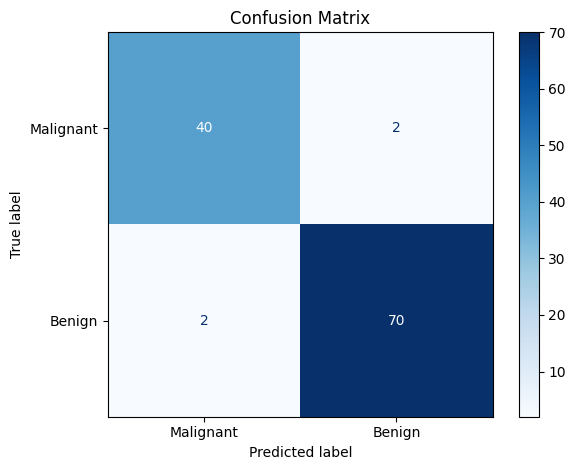

In [98]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix

winner_name = leaderboard.index[0]

if winner_name == "Tuned SVM":
    winner = grid_search.best_estimator_
elif winner_name == "Tuned KNN":
    winner = grid_search_knn.best_estimator_
elif winner_name == "Voting Ensemble":
    winner = voting_model
else:
    winner = ensembles[winner_name]

winner.fit(X_train, y_train)
y_pred = winner.predict(X_test)

print("Winning Model:", winner_name)
print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Malignant", "Benign"],
    cmap="Blues"
)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [99]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test

import joblib

joblib.dump(winner, "best_model.joblib")

loaded_model = joblib.load("best_model.joblib")

original_predictions = winner.predict(X_test.iloc[:5])
loaded_predictions = loaded_model.predict(X_test.iloc[:5])

print("Actual:", y_test.iloc[:5].tolist())
print("Original Predictions:", original_predictions.tolist())
print("Loaded Predictions:", loaded_predictions.tolist())
print("Predictions Match:", np.array_equal(original_predictions, loaded_predictions))

Actual: [0, 0, 1, 0, 1]
Original Predictions: [0, 0, 1, 0, 1]
Loaded Predictions: [0, 0, 1, 0, 1]
Predictions Match: True


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.
- **ANSWER:** Feature selection used the whole dataset, including the test data, which may cause data leakage and inflate CV scores. I would fix this by placing feature selection inside a Pipeline so it is fitted only on the training portion of each fold.

2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?
- **ANSWER:** I would report recall for the malignant class because it shows how many malignant cases the model correctly identifies. Accuracy alone is insufficient because a model can have high accuracy but still miss malignant cases.

3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)
- **ANSWER:** If two models differ by only 0.3% in CV accuracy, I would compare their scores across folds, interpretability, and training cost. I would prefer the model with more consistent results and simpler interpretation if their performance is nearly the same.

4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?
- **ANSWER:** With a much smaller dataset, the results may be less reliable because the model has fewer examples to learn from. With a more imbalanced dataset, accuracy may become misleading, so I would focus more on recall, precision, F1-score, and ROC-AUC.

5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.
- **ANSWER:** I would repeat the same process using another dataset, such as one loaded from an ARFF file. The data-loading code, target column, and preprocessing steps may change, but the model training, cross-validation, tuning, and evaluation process would remain simila

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.

In [104]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [101]:
#%cd /content/drive/MyDrive/ICT-110 Deocampo_Collab Works

In [102]:
!git config --global user.email "janadrian.deocampo@students.isatu.edu.ph"
!git config --global user.name "janadriandeocampo"
print('done')

done


In [103]:
!cp "/content/drive/MyDrive/ICT-110 Deocampo_Collab Works/Copy of ML_Workbook_Wisconsin_Diagnostic.ipynb" "/content/drive/MyDrive/IS110_BPerformance_Deocampo/IS110_repo_Deocampo"